# Step 3 - GNN Architecture and Training

This notebook trains four PyTorch models: GCN, GraphSAGE, GAT, and the homophily-gated GCN, from first-principles. It uses the sparse exports from `02-graph_engineering_baselines.ipynb`.

The experiment is transductive: all nodes and graph edges are used during message passing, but supervised loss is computed only on `labelled_train`. Validation macro-F1 selects the checkpoint; test scoring is intentionally separate.

In [1]:
from pathlib import Path
import sys
import torch
from IPython.display import display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from models import GNNClassifier
from pipeline_train import load_data, run_experiments

EXPORT_ROOT = ROOT / 'data/graph_engineering_50pc'
OUTPUT_ROOT = ROOT / 'data/gnn_training_50pc'
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
SEEDS = [42, 123, 2024]
print('PyTorch:', torch.__version__)
print('Device:', DEVICE)

PyTorch: 2.15.0
Device: cpu


## 1. Load the Step 2 contract

The loader checks the shared node order, split masks, graph, and budget-specific labels. Missing scarcity budgets are sampled per class from the original training pool with a fixed seed.

In [2]:
data = load_data(EXPORT_ROOT, budget='5pct', graph_name='knn', seed=42)
print('Features:', data.features.shape)
print('Edges:', data.edge_index.shape[1])
print('Labelled training nodes:', int(data.train_mask.sum()))
print('Validation nodes:', int(data.validation_mask.sum()))
print('Classes:', data.class_names)

Features: (65578, 50)
Edges: 1638524
Labelled training nodes: 1971
Validation nodes: 13116
Classes: ['CD14+ Monocyte', 'CD19+ B', 'CD34+', 'CD4+ T Helper2', 'CD4+/CD25 T Reg', 'CD4+/CD45RA+/CD25- Naive T', 'CD4+/CD45RO+ Memory', 'CD56+ NK', 'CD8+ Cytotoxic T', 'CD8+/CD45RA+ Naive Cytotoxic', 'Dendritic']


## 2. Smoke-test sparse layers

This small induced subgraph verifies that every architecture accepts weighted sparse edges and produces class logits without relying on PyTorch Geometric.

In [3]:
node_count = min(512, len(data.features))
edge_keep = (data.edge_index[0] < node_count) & (data.edge_index[1] < node_count)
small_x = torch.from_numpy(data.features[:node_count])
small_edges = torch.from_numpy(data.edge_index[:, edge_keep])
small_weights = torch.from_numpy(data.edge_weight[edge_keep])
for model_name in ['gcn', 'graphsage', 'gat', 'gated_gcn']:
    model = GNNClassifier(model_name, small_x.shape[1], 32, len(data.class_names), depth=2)
    logits = model(small_x, small_edges, small_weights)
    print(model_name, tuple(logits.shape))

gcn (512, 11)
graphsage (512, 11)
gat (512, 11)
gated_gcn (512, 11)


## 3. Main comparison

Set `RUN_MAIN = True` after the kernel and data exports are ready. The default uses both graph constructions, both existing label budgets, all four models, and three seeds. Results and checkpoints are written to `data/gnn_training_50pc/`.

In [4]:
RUN_MAIN = True
if RUN_MAIN:
    results = run_experiments(
        EXPORT_ROOT, OUTPUT_ROOT,
        budgets=['5pct', 'full'],
        graph_names=['knn', 'snn'],
        model_names=['gcn', 'graphsage', 'gat', 'gated_gcn'],
        depths=[2],
        seeds=SEEDS,
        epochs=200,
        device=DEVICE,
    )
    display(results.sort_values(['budget', 'graph', 'macro_f1'], ascending=[True, True, False]))

,accuracy,macro_f1,per_class_f1,model,seed,depth,hidden_features,best_epoch,epochs_run,budget,graph,mean_gate,validation_mean_gate
5,0.462412,0.405049,"{'CD14+ Monocyte': 0.7073170731707317, 'CD19+ ...",graphsage,2024,2,64,196,200,5pct,knn,NaN,NaN
4,0.456618,0.397176,"{'CD14+ Monocyte': 0.7149489322191273, 'CD19+ ...",graphsage,123,2,64,176,200,5pct,knn,NaN,NaN
7,0.418801,0.396173,"{'CD14+ Monocyte': 0.7075393537696769, 'CD19+ ...",gat,123,2,64,77,102,5pct,knn,NaN,NaN
3,0.449909,0.395318,"{'CD14+ Monocyte': 0.7136060894386299, 'CD19+ ...",graphsage,42,2,64,129,154,5pct,knn,NaN,NaN
11,0.450900,0.394098,"{'CD14+ Monocyte': 0.7061032863849765, 'CD19+ ...",gated_gcn,2024,2,64,200,200,5pct,knn,0.851991,0.851596
9,0.442513,0.390406,"{'CD14+ Monocyte': 0.712022367194781, 'CD19+ B...",gated_gcn,42,2,64,200,200,5pct,knn,0.829912,0.829815
6,0.435575,0.390162,"{'CD14+ Monocyte': 0.6778242677824268, 'CD19+ ...",gat,42,2,64,199,200,5pct,knn,NaN,NaN
10,0.452272,0.388694,"{'CD14+ Monocyte': 0.7015902712815716, 'CD19+ ...",gated_gcn,123,2,64,200,200,5pct,knn,0.856969,0.856955
8,0.418649,0.373654,"{'CD14+ Monocyte': 0.6078740157480315, 'CD19+ ...",gat,2024,2,64,66,91,5pct,knn,NaN,NaN
0,0.418954,0.372442,"{'CD14+ Monocyte': 0.7422096317280453, 'CD19+ ...",gcn,42,2,64,196,200,5pct,knn,NaN,NaN


## 4. Scarcity and depth ablations

The loader supports `1pct`, `2pct`, `5pct`, `10pct`, `20pct`, and `full`. Depth values are passed to the same training function so the comparison keeps graph, masks, optimizer, and checkpoint rules fixed. Run these as separate jobs if the full matrix is too large for one kernel session.

In [5]:
RUN_ABLATIONS = True
if RUN_ABLATIONS:
    scarcity_results = run_experiments(
        EXPORT_ROOT, OUTPUT_ROOT / 'scarcity',
        budgets=['1pct', '2pct', '5pct', '10pct', '20pct', 'full'],
        graph_names=['knn'],
        model_names=['gcn', 'gated_gcn'],
        depths=[2],
        seeds=SEEDS,
        epochs=200,
        device=DEVICE,
    )
    depth_results = run_experiments(
        EXPORT_ROOT, OUTPUT_ROOT / 'depth',
        budgets=['5pct'],
        graph_names=['knn'],
        model_names=['gcn', 'gated_gcn'],
        depths=[1, 2, 3, 4],
        seeds=SEEDS,
        epochs=200,
        device=DEVICE,
    )
    display(scarcity_results)
    display(depth_results)

,accuracy,macro_f1,per_class_f1,model,seed,depth,hidden_features,best_epoch,epochs_run,budget,graph,mean_gate,validation_mean_gate
0,0.389524,0.344226,"{'CD14+ Monocyte': 0.7000946073793756, 'CD19+ ...",gcn,42,2,64,199,200,1pct,knn,NaN,NaN
1,0.366041,0.321005,"{'CD14+ Monocyte': 0.7220683287165282, 'CD19+ ...",gcn,123,2,64,146,171,1pct,knn,NaN,NaN
2,0.380375,0.329842,"{'CD14+ Monocyte': 0.7055503292568204, 'CD19+ ...",gcn,2024,2,64,188,200,1pct,knn,NaN,NaN
3,0.420708,0.318596,"{'CD14+ Monocyte': 0.6309403437815976, 'CD19+ ...",gated_gcn,42,2,64,199,200,1pct,knn,0.918067,0.918038
4,0.414761,0.337480,"{'CD14+ Monocyte': 0.6055776892430279, 'CD19+ ...",gated_gcn,123,2,64,187,200,1pct,knn,0.933972,0.934134
5,0.422690,0.369256,"{'CD14+ Monocyte': 0.6640548481880509, 'CD19+ ...",gated_gcn,2024,2,64,200,200,1pct,knn,0.908829,0.908743
6,0.409347,0.363683,"{'CD14+ Monocyte': 0.7313432835820896, 'CD19+ ...",gcn,42,2,64,200,200,2pct,knn,NaN,NaN
7,0.409271,0.360189,"{'CD14+ Monocyte': 0.7288135593220338, 'CD19+ ...",gcn,123,2,64,200,200,2pct,knn,NaN,NaN
8,0.395547,0.356247,"{'CD14+ Monocyte': 0.7220683287165282, 'CD19+ ...",gcn,2024,2,64,199,200,2pct,knn,NaN,NaN
9,0.431915,0.381957,"{'CD14+ Monocyte': 0.7050228310502283, 'CD19+ ...",gated_gcn,42,2,64,199,200,2pct,knn,0.901049,0.901121


,accuracy,macro_f1,per_class_f1,model,seed,depth,hidden_features,best_epoch,epochs_run,budget,graph,mean_gate,validation_mean_gate
0,0.279963,0.260364,"{'CD14+ Monocyte': 0.5620542082738944, 'CD19+ ...",gcn,42,1,64,200,200,5pct,knn,NaN,NaN
1,0.339814,0.297731,"{'CD14+ Monocyte': 0.5829228243021346, 'CD19+ ...",gcn,123,1,64,200,200,5pct,knn,NaN,NaN
2,0.263495,0.255775,"{'CD14+ Monocyte': 0.6150409530900968, 'CD19+ ...",gcn,2024,1,64,200,200,5pct,knn,NaN,NaN
3,0.418954,0.372442,"{'CD14+ Monocyte': 0.7422096317280453, 'CD19+ ...",gcn,42,2,64,196,200,5pct,knn,NaN,NaN
4,0.388533,0.368869,"{'CD14+ Monocyte': 0.7159603246167718, 'CD19+ ...",gcn,123,2,64,118,143,5pct,knn,NaN,NaN
5,0.407975,0.367106,"{'CD14+ Monocyte': 0.7303689687795648, 'CD19+ ...",gcn,2024,2,64,198,200,5pct,knn,NaN,NaN
6,0.435956,0.370857,"{'CD14+ Monocyte': 0.7166666666666667, 'CD19+ ...",gcn,42,3,64,76,101,5pct,knn,NaN,NaN
7,0.388533,0.376383,"{'CD14+ Monocyte': 0.7281191806331471, 'CD19+ ...",gcn,123,3,64,82,107,5pct,knn,NaN,NaN
8,0.433821,0.383341,"{'CD14+ Monocyte': 0.7455731593662628, 'CD19+ ...",gcn,2024,3,64,186,200,5pct,knn,NaN,NaN
9,0.190454,0.222474,"{'CD14+ Monocyte': 0.6030267753201397, 'CD19+ ...",gcn,42,4,64,8,33,5pct,knn,NaN,NaN


## 5. Reporting checklist

Report mean and standard deviation across seeds for accuracy and macro-F1, per-class F1 for all 11 classes, validation-selected epoch, and the gated model's mean gate value. Keep test scoring disabled until model, graph, depth, budget, and checkpoint rules are fixed.

,experiment,budget,graph,model,depth,hidden_features,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,best_epoch_mean,best_epoch_std,epochs_run_mean,epochs_run_std,mean_gate_mean,mean_gate_std,validation_mean_gate_mean,validation_mean_gate_std
0,depth,5pct,knn,gated_gcn,1,64,0.291832,0.028050,0.268059,0.017211,200.000000,0.000000,200.000000,0.000000,0.508937,0.004476,0.508622,0.004451
1,depth,5pct,knn,gated_gcn,2,64,0.448562,0.005283,0.391066,0.002762,200.000000,0.000000,200.000000,0.000000,0.846291,0.014401,0.846122,0.014374
2,depth,5pct,knn,gated_gcn,3,64,0.224408,0.152692,0.247645,0.107115,34.333333,39.551654,59.333333,39.551654,0.607183,0.178371,0.607120,0.178273
3,depth,5pct,knn,gated_gcn,4,64,0.369752,0.076134,0.348662,0.071499,97.666667,84.807625,121.666667,83.392646,0.566259,0.055341,0.566233,0.055322
4,depth,5pct,knn,gcn,1,64,0.294424,0.040162,0.271290,0.023013,200.000000,0.000000,200.000000,0.000000,NaN,NaN,NaN,NaN
5,depth,5pct,knn,gcn,2,64,0.405154,0.015405,0.369472,0.002718,170.666667,45.621632,181.000000,32.908965,NaN,NaN,NaN,NaN
6,depth,5pct,knn,gcn,3,64,0.419437,0.026785,0.376861,0.006256,114.666667,61.849279,136.000000,55.506756,NaN,NaN,NaN,NaN
7,depth,5pct,knn,gcn,4,64,0.329877,0.120947,0.311506,0.077653,50.666667,36.963946,75.666667,36.963946,NaN,NaN,NaN,NaN
8,main,5pct,knn,gat,2,64,0.424342,0.009728,0.386663,0.011660,114.000000,73.817342,131.000000,60.008333,NaN,NaN,NaN,NaN
9,main,5pct,knn,gated_gcn,2,64,0.448562,0.005283,0.391066,0.002762,200.000000,0.000000,200.000000,0.000000,0.846291,0.014401,0.846122,0.014374


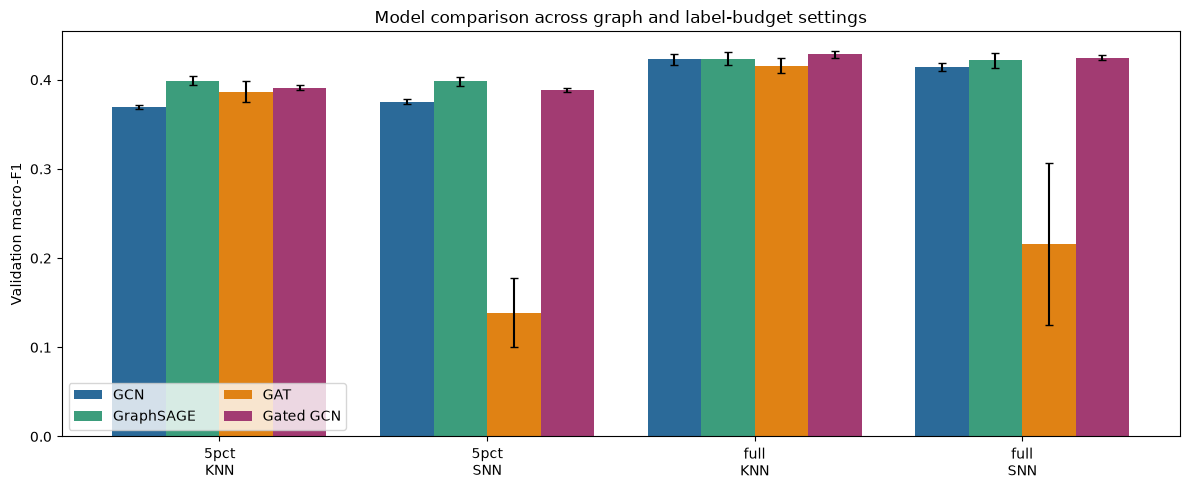

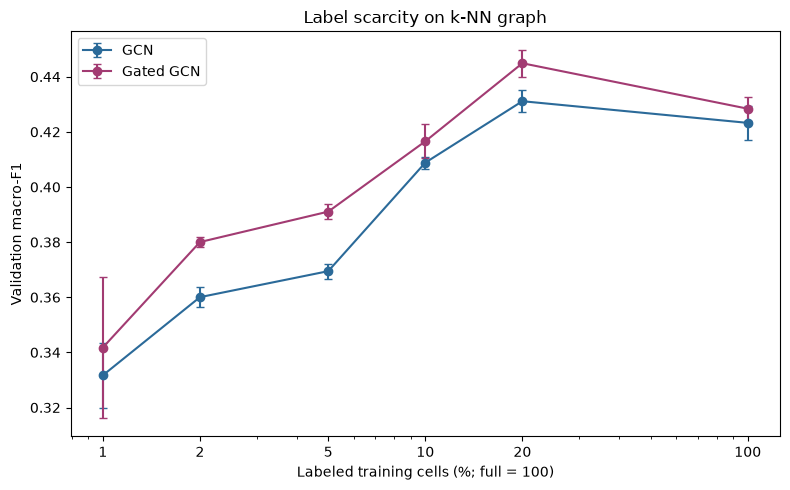

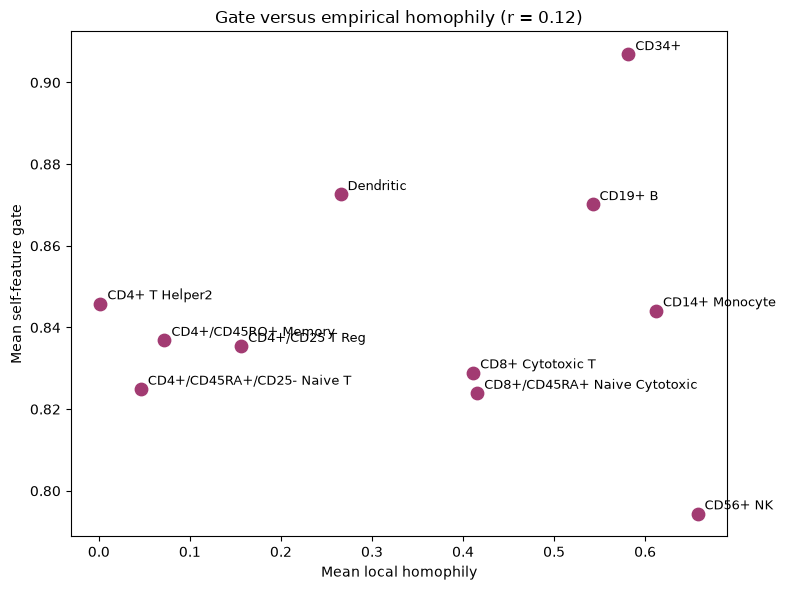

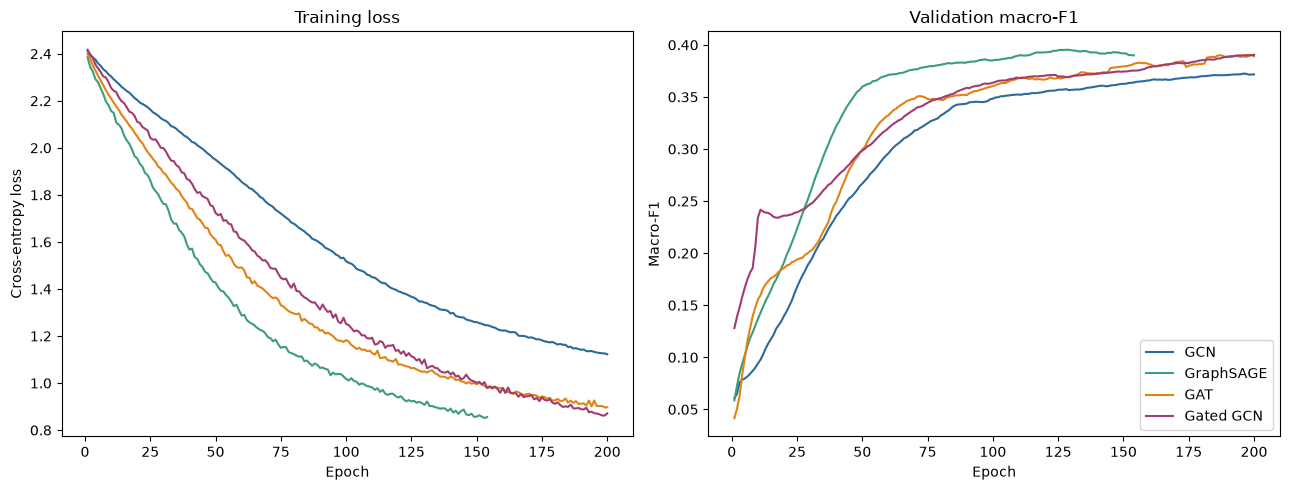

Plots saved to data/gnn_training_50pc/plots


In [6]:
import ast
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Summarise the per-run validation results written above: mean and std over seeds,
# saved to reporting/ as experiment_summary.csv and per_class_f1_summary.csv.
frames = []
for experiment, folder in [("main", OUTPUT_ROOT), ("scarcity", OUTPUT_ROOT / "scarcity"), ("depth", OUTPUT_ROOT / "depth")]:
    path = folder / "validation_results.csv"
    if path.is_file():
        frames.append(pd.read_csv(path).assign(experiment=experiment))
runs = pd.concat(frames, ignore_index=True)
keys = ["experiment", "budget", "graph", "model", "depth", "hidden_features"]
metrics = ["accuracy", "macro_f1", "best_epoch", "epochs_run", "mean_gate", "validation_mean_gate"]
summary = runs.groupby(keys, as_index=False)[metrics].agg(["mean", "std"])
summary.columns = [f"{m}_{s}" if s else m for m, s in summary.columns]
per_class = pd.concat([runs[keys], runs["per_class_f1"].map(ast.literal_eval).apply(pd.Series)], axis=1)
per_class = per_class.melt(id_vars=keys, var_name="class_name", value_name="f1")
per_class_summary = per_class.groupby(keys + ["class_name"], as_index=False)["f1"].agg(["mean", "std"])
per_class_summary = per_class_summary.rename(columns={"mean": "f1_mean", "std": "f1_std"})
report_root = OUTPUT_ROOT / "reporting"
report_root.mkdir(exist_ok=True)
summary.to_csv(report_root / "experiment_summary.csv", index=False)
per_class_summary.to_csv(report_root / "per_class_f1_summary.csv", index=False)
display(summary)

LABELS = {"gcn": "GCN", "graphsage": "GraphSAGE", "gat": "GAT", "gated_gcn": "Gated GCN"}
COLORS = {"gcn": "#2b6a99", "graphsage": "#3c9d7c", "gat": "#e08214", "gated_gcn": "#a23b72"}
PLOTS = OUTPUT_ROOT / "plots"
PLOTS.mkdir(exist_ok=True)

# 1. Main comparison: four models, two graphs, two budgets
main = summary[summary.experiment == "main"]
settings = [(b, g) for b in ["5pct", "full"] for g in ["knn", "snn"]]
fig, ax = plt.subplots(figsize=(12, 5))
bar_width = 0.2
for k, model in enumerate(LABELS):
    rows = [main[(main.budget == b) & (main.graph == g) & (main.model == model)].iloc[0] for b, g in settings]
    ax.bar(np.arange(len(settings)) + (k - 1.5) * bar_width, [r.macro_f1_mean for r in rows], bar_width,
           yerr=[r.macro_f1_std for r in rows], capsize=3, color=COLORS[model], label=LABELS[model])
ax.set_xticks(np.arange(len(settings)), [f"{b}\n{g.upper()}" for b, g in settings])
ax.set_ylabel("Validation macro-F1")
ax.set_title("Model comparison across graph and label-budget settings")
ax.legend(ncol=2)
fig.tight_layout(); fig.savefig(PLOTS / "model_comparison.png", dpi=150); plt.show()

# 2. Scarcity curve on the k-NN graph
scarcity = summary[summary.experiment == "scarcity"]
percent = {"1pct": 1, "2pct": 2, "5pct": 5, "10pct": 10, "20pct": 20, "full": 100}
fig, ax = plt.subplots(figsize=(8, 5))
for model in ["gcn", "gated_gcn"]:
    rows = scarcity[scarcity.model == model].assign(x=lambda d: d.budget.map(percent)).sort_values("x")
    ax.errorbar(rows.x, rows.macro_f1_mean, yerr=rows.macro_f1_std, marker="o", capsize=3,
                color=COLORS[model], label=LABELS[model])
ax.set_xscale("log")
ax.set_xticks(list(percent.values()), [str(v) for v in percent.values()])
ax.set_xlabel("Labeled training cells (%; full = 100)")
ax.set_ylabel("Validation macro-F1")
ax.set_title("Label scarcity on k-NN graph")
ax.legend()
fig.tight_layout(); fig.savefig(PLOTS / "scarcity_curve.png", dpi=150); plt.show()

# 3. Class-level gate versus local homophily (gated GCN, 5 % k-NN, seed 42)
stem = "gated_gcn_5pct_knn_depth2_seed42"
gate = np.load(OUTPUT_ROOT / f"{stem}_gate_values.npy").mean(axis=1)
gate_meta = pd.read_csv(OUTPUT_ROOT / f"{stem}_gate_values_metadata.csv").assign(gate=gate)
by_class = gate_meta.groupby("celltype")[["gate", "local_homophily"]].mean()
r = np.corrcoef(by_class.local_homophily, by_class.gate)[0, 1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(by_class.local_homophily, by_class.gate, s=80, color=COLORS["gated_gcn"])
for name, row in by_class.iterrows():
    ax.annotate(name, (row.local_homophily, row.gate), xytext=(5, 3), textcoords="offset points", fontsize=9)
ax.set_xlabel("Mean local homophily")
ax.set_ylabel("Mean self-feature gate")
ax.set_title(f"Gate versus empirical homophily (r = {r:.2f})")
fig.tight_layout(); fig.savefig(PLOTS / "gate_vs_homophily.png", dpi=150); plt.show()

# 4. Training dynamics (5 % k-NN, depth 2, seed 42)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for model in LABELS:
    history = pd.DataFrame(json.loads((OUTPUT_ROOT / f"{model}_5pct_knn_depth2_seed42.json").read_text())["history"])
    axes[0].plot(history.epoch, history.loss, color=COLORS[model], label=LABELS[model])
    axes[1].plot(history.epoch, history.val_macro_f1, color=COLORS[model], label=LABELS[model])
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[1].set(title="Validation macro-F1", xlabel="Epoch", ylabel="Macro-F1")
axes[1].legend()
fig.tight_layout(); fig.savefig(PLOTS / "training_dynamics.png", dpi=150); plt.show()
print("Plots saved to", PLOTS.relative_to(ROOT))
